# Predictive Customer Churn Classifier (Random Forest & XGBoost)

**Goal:** Predict which telecom customers will churn (leave), handle class imbalance, and reach **ROC-AUC > 0.80**.

**Steps:** Load → Clean `TotalCharges` → EDA → OneHotEncoder → Stratified split → Balance classes (**SMOTE** for Random Forest, **scale_pos_weight** for XGBoost) → 5-fold CV → Test evaluation → ROC curves → Confusion matrices → Top 10 feature importances.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, accuracy_score, precision_score,
                             recall_score, f1_score)
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline   # applies SMOTE only on training data
from imblearn.over_sampling import SMOTE

sns.set_style("whitegrid")
RANDOM_STATE = 42

## 2. Load the Telco Customer Churn dataset

In [2]:
df = pd.read_csv("telco_churn.csv")
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 3. Convert `TotalCharges` to numeric and handle nulls
`TotalCharges` is stored as text because some rows contain a blank space. `pd.to_numeric(errors='coerce')` turns those into `NaN`.

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Null TotalCharges:", df["TotalCharges"].isnull().sum())
df[df["TotalCharges"].isnull()][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Null TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


All these rows have `tenure = 0` (brand new customers who have not been billed yet), so their real total charge is **0**. We fill the nulls with 0, which is more accurate than using the median.

In [5]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("Remaining nulls in whole dataset:", df.isnull().sum().sum())

Remaining nulls in whole dataset: 0


## 4. Class imbalance check

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn rate: 26.54%
Imbalance ratio (No : Yes) = 2.77 : 1


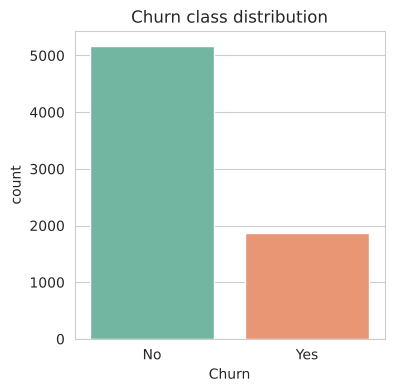

In [6]:
counts = df["Churn"].value_counts()
print(counts)
print(f"\nChurn rate: {(df['Churn'] == 'Yes').mean():.2%}")
print(f"Imbalance ratio (No : Yes) = {counts['No'] / counts['Yes']:.2f} : 1")

plt.figure(figsize=(4, 4))
sns.countplot(x="Churn", data=df, palette="Set2", hue="Churn", legend=False)
plt.title("Churn class distribution")
plt.show()

**Note:** About 26.5% of customers churn, about 2.8 non-churners for every churner. This is a **moderate** imbalance, not an extreme one. It is still enough that a model can score high accuracy by mostly predicting "No", so we balance the classes and judge with ROC-AUC, recall and F1 instead of accuracy alone.

## 5. Quick EDA: what relates to churn?

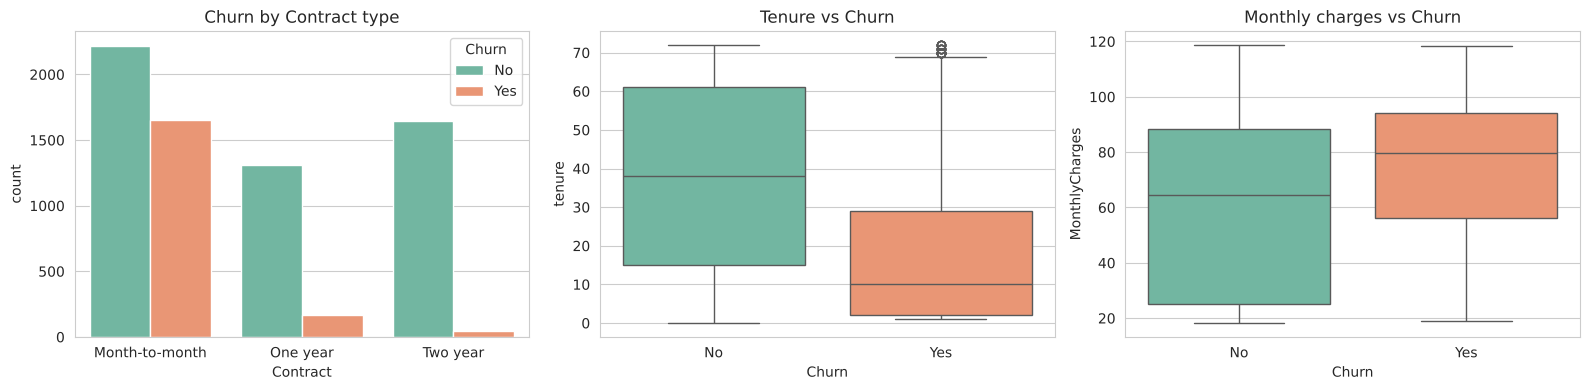

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x="Contract", hue="Churn", data=df, ax=axes[0], palette="Set2")
axes[0].set_title("Churn by Contract type")
sns.boxplot(x="Churn", y="tenure", data=df, ax=axes[1], palette="Set2", hue="Churn", legend=False)
axes[1].set_title("Tenure vs Churn")
sns.boxplot(x="Churn", y="MonthlyCharges", data=df, ax=axes[2], palette="Set2", hue="Churn", legend=False)
axes[2].set_title("Monthly charges vs Churn")
plt.tight_layout()
plt.show()

## 6. Prepare features and target
- `customerID` is just an ID, so it is dropped.
- Target: `Churn` → 1 = Yes, 0 = No.

In [8]:
X = df.drop(columns=["customerID", "Churn"])
y = (df["Churn"] == "Yes").astype(int)

cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
print("Categorical:", cat_cols)
print("Numeric:", num_cols)

Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


/tmp/ipykernel_143/1719885293.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include="object").columns.tolist()


## 7. Stratified train/test split (80/20)
`stratify=y` keeps the same churn percentage in train and test.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (5634, 19) | Test: (1409, 19)
Churn rate train: 0.265 | test: 0.265


## 8. Preprocessing with OneHotEncoder
Categorical columns → One-Hot encoding. Numeric columns → StandardScaler (helps SMOTE, which measures distances between samples).

In [10]:
preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ("num", StandardScaler(), num_cols),
])

## 9. Balance the classes and build the two models
- **Random Forest + SMOTE:** SMOTE creates synthetic churn samples. It is inside an `imblearn` Pipeline, so it runs **only on training data** (never on validation folds or the test set).
- **XGBoost + `scale_pos_weight`:** gives churn samples a higher weight = (number of No) / (number of Yes).

In [11]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight for XGBoost: {scale_pos_weight:.2f}")

rf_model = ImbPipeline([
    ("prep", preprocess),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=3,
                                     random_state=RANDOM_STATE, n_jobs=-1)),
])

xgb_model = ImbPipeline([
    ("prep", preprocess),
    ("model", XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3,
                            subsample=0.8, colsample_bytree=0.8,
                            scale_pos_weight=scale_pos_weight,
                            eval_metric="auc", random_state=RANDOM_STATE, n_jobs=-1)),
])
models = {"Random Forest (SMOTE)": rf_model, "XGBoost (scale_pos_weight)": xgb_model}

scale_pos_weight for XGBoost: 2.77


### Visual check: what SMOTE does to the training data

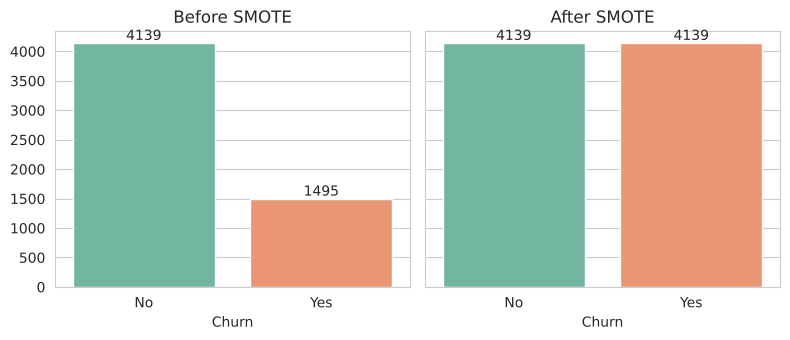

In [12]:
X_prep = preprocess.fit_transform(X_train)
X_res, y_res = SMOTE(random_state=RANDOM_STATE).fit_resample(X_prep, y_train)

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), sharey=True)
for ax, labels, title in zip(axes, [y_train, y_res], ["Before SMOTE", "After SMOTE"]):
    vc = pd.Series(labels).map({0: "No", 1: "Yes"}).value_counts()
    sns.barplot(x=vc.index, y=vc.values, ax=ax, palette="Set2", hue=vc.index, legend=False)
    ax.set_title(title)
    for i, v in enumerate(vc.values):
        ax.text(i, v, v, ha="center", va="bottom")
plt.tight_layout()
plt.show()

## 10. Cross-validation (5-fold, ROC-AUC)

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, m in models.items():
    scores = cross_val_score(m, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
    cv_rows.append({"Model": name, "CV ROC-AUC (mean)": scores.mean(), "CV ROC-AUC (std)": scores.std()})
cv_results = pd.DataFrame(cv_rows).set_index("Model").round(4)
cv_results

,CV ROC-AUC (mean),CV ROC-AUC (std)
Model,,
Random Forest (SMOTE),0.8400,0.0079
XGBoost (scale_pos_weight),0.8476,0.0106


## 11. Train on full training set and evaluate on the test set

In [14]:
probs, preds, rows = {}, {}, []
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict_proba(X_test)[:, 1]
    y_pred = (p >= 0.5).astype(int)
    probs[name], preds[name] = p, y_pred
    rows.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, p),
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (churn)": precision_score(y_test, y_pred),
        "Recall (churn)": recall_score(y_test, y_pred),
        "F1 (churn)": f1_score(y_test, y_pred),
    })
results = pd.DataFrame(rows).set_index("Model").round(4)
results

,ROC-AUC,Accuracy,Precision (churn),Recall (churn),F1 (churn)
Model,,,,,
Random Forest (SMOTE),0.8344,0.7665,0.5501,0.6604,0.6002
XGBoost (scale_pos_weight),0.8457,0.7523,0.5221,0.7888,0.6283


In [15]:
for name, y_pred in preds.items():
    print("=" * 55); print(name); print("=" * 55)
    print(classification_report(y_test, y_pred, target_names=["No churn", "Churn"], digits=3))
print("ROC-AUC > 0.80 requirement met:",
      {n: bool(a > 0.80) for n, a in results["ROC-AUC"].items()})

Random Forest (SMOTE)
              precision    recall  f1-score   support

    No churn      0.868     0.805     0.835      1035
       Churn      0.550     0.660     0.600       374

    accuracy                          0.767      1409
   macro avg      0.709     0.733     0.718      1409
weighted avg      0.783     0.767     0.773      1409

XGBoost (scale_pos_weight)
              precision    recall  f1-score   support

    No churn      0.906     0.739     0.814      1035
       Churn      0.522     0.789     0.628       374

    accuracy                          0.752      1409
   macro avg      0.714     0.764     0.721      1409
weighted avg      0.804     0.752     0.765      1409

ROC-AUC > 0.80 requirement met: {'Random Forest (SMOTE)': True, 'XGBoost (scale_pos_weight)': True}


## 12. ROC curves

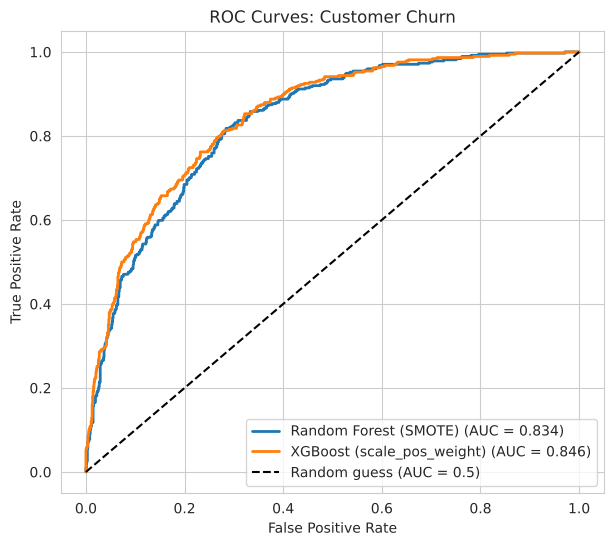

In [16]:
plt.figure(figsize=(7, 6))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves: Customer Churn")
plt.legend(loc="lower right")
plt.show()

## 13. Confusion matrices (threshold = 0.5)

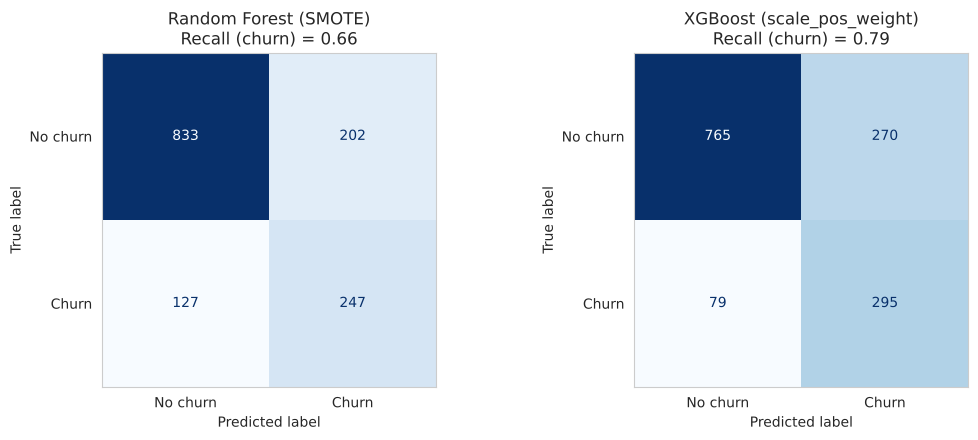

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, y_pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=["No churn", "Churn"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}\nRecall (churn) = {recall_score(y_test, y_pred):.2f}")
    ax.grid(False)
plt.tight_layout()
plt.show()

## 14. Top 10 most influential features

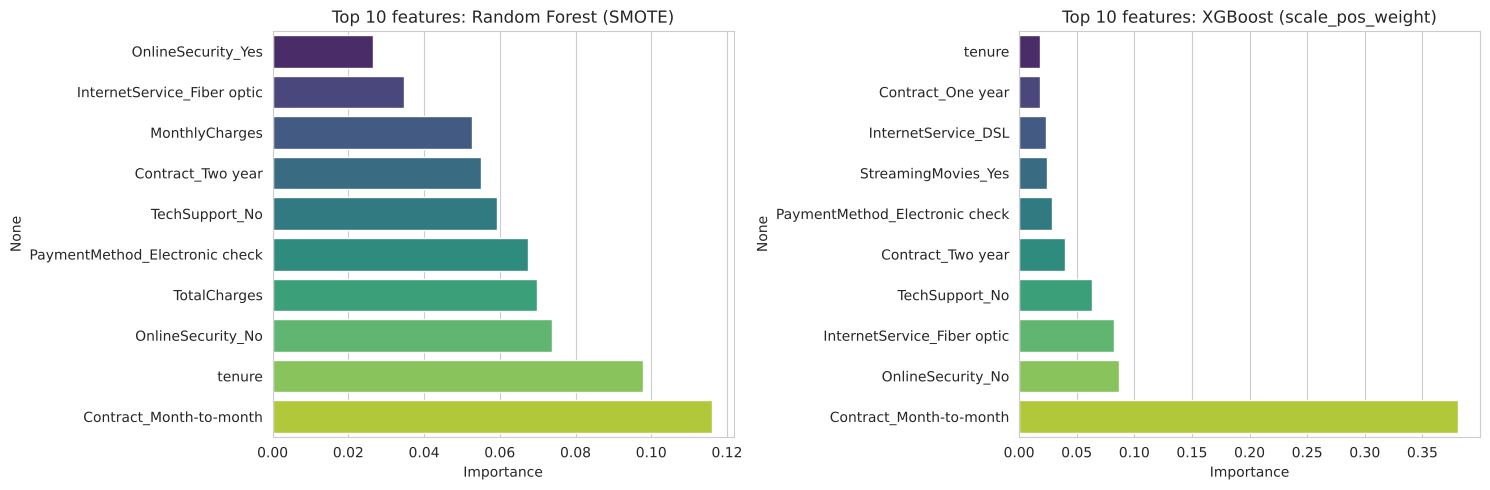

,Random Forest (SMOTE),XGBoost (scale_pos_weight)
1,Contract_Month-to-month,Contract_Month-to-month
2,tenure,OnlineSecurity_No
3,OnlineSecurity_No,InternetService_Fiber optic
4,TotalCharges,TechSupport_No
5,PaymentMethod_Electronic check,Contract_Two year
6,TechSupport_No,PaymentMethod_Electronic check
7,Contract_Two year,StreamingMovies_Yes
8,MonthlyCharges,InternetService_DSL
9,InternetService_Fiber optic,Contract_One year
10,OnlineSecurity_Yes,tenure


In [18]:
feature_names = np.array([f.split("__")[1] for f in
                          rf_model.named_steps["prep"].get_feature_names_out()])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
top10 = {}
for ax, (name, m) in zip(axes, models.items()):
    imp = pd.Series(m.named_steps["model"].feature_importances_, index=feature_names)
    top = imp.sort_values(ascending=False).head(10)
    top10[name] = top
    sns.barplot(x=top.values[::-1], y=top.index[::-1], ax=ax, palette="viridis", hue=top.index[::-1], legend=False)
    ax.set_title(f"Top 10 features: {name}")
    ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

pd.DataFrame({k: v.index.tolist() for k, v in top10.items()}, index=range(1, 11))

## 15. Conclusion

In [19]:
print(results[["ROC-AUC", "Recall (churn)", "F1 (churn)"]])
print("\nBest ROC-AUC:", results["ROC-AUC"].idxmax())

                            ROC-AUC  Recall (churn)  F1 (churn)
Model                                                          
Random Forest (SMOTE)        0.8344          0.6604      0.6002
XGBoost (scale_pos_weight)   0.8457          0.7888      0.6283

Best ROC-AUC: XGBoost (scale_pos_weight)


**Observations**
- Both models pass the **ROC-AUC > 0.80** requirement on the held-out test set.
- With balancing, the models catch many churners: XGBoost has recall of about 79% and Random Forest about 66%. Accuracy (about 75-77%) is lower than recall because the model accepts some false alarms. For churn, missing a leaving customer is usually more costly than a false alarm, so this trade-off is acceptable.
- XGBoost has the higher ROC-AUC and recall, while Random Forest has slightly higher precision and accuracy.
- The top features are **contract type** (month-to-month), **tenure**, **no online security**, **no tech support**, **fiber optic internet** and **electronic check payment**. Customers on month-to-month contracts with short tenure churn the most.
- The 0.5 threshold is a default. A business could lower it to catch even more churners, at the cost of more false positives.
- SMOTE is applied inside the pipeline, so synthetic samples are never created from validation or test data (no data leakage).